## Oppgave 3d)

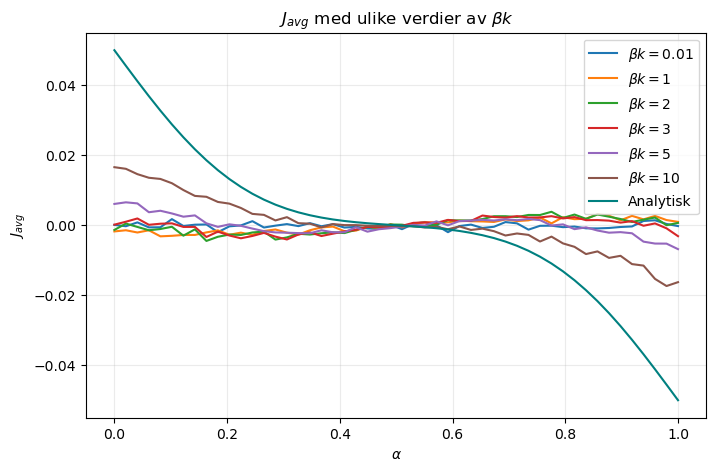

In [6]:
import numpy as np
import math
import matplotlib.pyplot as plt

h = 1
N_x = 100
P = 2 * N_x     
N_p = 12 * N_x
T_p = 500

Beta_k_vals = [0.01, 1, 2, 3, 5, 10]

alpha_vals = np.linspace(0, 1, 50)

def J_ana(alpha):

    sqr = np.sqrt(3 / T_p)
    a = ((alpha * N_x) / 2) * sqr
    b = (((1 - alpha) * N_x) / 2) * sqr
    return (N_x / (4 * T_p) ) * (math.erfc(a) - math.erfc(b))

    

def build_V1(alpha, N_x):
    peak = int(alpha * (N_x - 1))
    n = np.arange(N_x)
    V = np.zeros(N_x, dtype=float)

    left = (n <= peak)
    right = (n > peak)

    V[left]  = n[left] / max(peak, 1)
    V[right] = (N_x - 1 - n[right]) / max((N_x - 1 - peak), 1)

    return np.concatenate([V, V])

V2 = np.zeros(P)
plt.figure(figsize=(8, 5))

for Beta_k in Beta_k_vals:

    J_num = np.zeros_like(alpha_vals, dtype=float)

    for i, alpha in enumerate(alpha_vals):

        V1 = build_V1(alpha, N_x)
    
        x = np.array(int(N_p / 2) * [0, N_x], dtype=int) 

        J_sum = 0

        for j in range(2 * T_p):
        
            if (j < T_p):
                V = V2
            else:
                V = V1
                
            V_l = V[(x - 1) % P]
            V_0 = V[x]
            V_r = V[(x + 1) % P]

            p_plus  = 1 / (1 + np.exp(-Beta_k*(V_l - V_r)) + np.exp(-Beta_k*(V_0 - V_r)))
            p_minus = 1 / (1 + np.exp(-Beta_k*(V_r - V_l)) + np.exp(-Beta_k*(V_0 - V_l)))
    
            r = np.random.rand(N_p)
    
            pos = np.zeros_like(x) # tomt array med posisjon 0
            pos[r < p_minus] = -1
            pos[r > 1 - p_plus] = +1

            n_plus  = np.sum(pos == 1) # teller hvor mange partikelr som gikk til høyre
            n_minus = np.sum(pos == -1) # teller hvor mange partikelr som gikk til venstre
            J_t = (n_plus - n_minus) / N_p  # current J[i]

            J_sum += J_t
            x = (x + pos) % P  # randbet, x0 -> x199
        

        J_num[i] = J_sum / (2 * T_p)

    plt.plot(alpha_vals, J_num, label=rf"$\beta k = {Beta_k}$")

J_analytical = np.zeros_like(alpha_vals, dtype=float)

for i, alpha in enumerate(alpha_vals):
    J_analytical[i] = J_ana(alpha)
    
plt.plot(alpha_vals, J_analytical, label="Analytisk", color = "teal")
plt.grid(alpha=0.25)
plt.xlabel(r"$\alpha$")
plt.ylabel("$J_{avg}$")
plt.title(r"$J_{avg}$ med ulike verdier av $\beta k$")
plt.legend(loc = "upper right")
plt.show()

##### Kommentar til kode:

Plottet ovenfor viser hvordan $J_{avg}$ fra oppgave 3c varierer med ulike verdier insatt for $\beta k$. Resultatet viser at $J_{avg}$ ikke bare avhenger av $\alpha$, men også av temperatur, $\beta = (k_b T)^{-1}$. Høye temperaturer resulterer i lave verdier for $\beta k$ som gir $e ^{- \beta V(x)} \approx 1$. Dermed blir strømmen uavhengig av potensialet som resulterer i at $J_{avg} \approx 0$ for lave verdier av $\beta k$ som observert i plottet. Med økende $\beta k$ får potensialt en innvirkning på bevgelsen, og netto strøm vil oppstå. For $\beta k \in (5, 10)$ følger $J_{avg}$  samme trend som for den analytiske løsningen. Positiv strøm for $\alpha < 0.5$, og negativ for $\alpha > 0.5$. For $\alpha = 0$ er systemet symmetrisk, og det vil ikke oppstå netto strøm uavhengig av verdien til $\beta k$.

Den analytiske kurven viser hvordan systemet ideelt sett vil oppføre seg, og hvor potensialet styrer bevegeslen. Denne antakelsen vil brytes for små verdier av $\beta k$ som observert i plottet. Lave verdier av $\beta k$ resulterer i tilfeldige bevegelser fra temepraturen, altså støy. Dermed vil den numeriske modellen samsvare dårlig med den analytiske ettersom den analytsike løsningen legger til grunn at bevegelsen kun påvirkes av sagtann-potensialet. Økende $\beta k$ gir redusert støy og en tydeligere retningsbasert strøm. Samlet sett vsier dette at $\beta k$ har en innvirkning på balansen mellom støy og sterkt potensialet påvirker bevegelsen. 